# M13.6-rev — Simetría temporal del ruido del banco de aumentación

La aumentación de M13.6 invierte en el tiempo L(n) con probabilidad 0,5 (`docs/experiments/M13_6_noise_augmentation.md` §5). Esa inversión solo es inocua si el ruido del banco no distingue el sentido del tiempo. Este notebook lo comprueba por detector (H1, L1, V1).

**Datos:** `<data_root>/processed/M13_G3_band1024_w16_500k/m13_6_aug/memmap/bank_X.npy`, L(n) antes del z-score, float16, (12800, 3, 16384), 200 claves `psd_key` × K = 64, ordenado por (psd_key, k). fs = 4096 Hz, ventana de 4 s. Se procesa por bloques de `psd_key` y cada realización se normaliza con el z-score de §5, (x − media)/(std + 1e-6).

**Ejecutar una vez, de arriba abajo.** Las salidas se escriben en modo `x`: si ya existen, el notebook aborta antes de calcular.

## Medidas
1. Estacionariedad: E[z(t)²] por muestra. Se usa E[z²] como varianza porque z tiene media ≈ 0.
2. Espectro por tramos: Welch (Hann, 1024 muestras, solape 50 %) en el primer cuarto, la mitad central y el último cuarto; cocientes entre tramos.
3. Gaussianidad: asimetría y curtosis en exceso por realización; media e IC 95 % por bootstrap sobre realizaciones.
4. Irreversibilidad: A(τ) = E[x(t)²·x(t+τ)] − E[x(t)·x(t+τ)²], τ = 1..64, sobre z (σ = 1, ya normalizado por σ³). Bootstrap sobre realizaciones, B = 1000, `default_rng(1361)`. Controles: ruido invertido y ruido gaussiano blanco sintético del mismo tamaño.

## Lectura fijada de antemano
"Simetría compatible" si se cumplen las cuatro condiciones:
- (a) las desviaciones de varianza > 2 % se limitan a ≤ 0,1 s de cada borde;
- (b) los cocientes de PSD entre tramos están dentro de ±5 % en 30–1024 Hz;
- (c) |curtosis en exceso| y |asimetría| tienen IC que incluye 0 o son < 0,05;
- (d) A(τ) es compatible con 0 para todo τ.

## Enmienda a la lectura (6-11-2026, antes de ejecutar)
Dos condiciones, leídas literalmente, fallarían también con ruido ideal. Decidido antes de ver ningún dato:
- **(a):** el error por muestra es √(2/12800) ≈ 1,25 %, así que ≈ 11 % de las muestras superaría el 2 % por azar. El veredicto usa la varianza suavizada con media móvil de 64 muestras (≈ 16 ms; ventana truncada en los bordes). La referencia es la mediana de la curva suavizada en la mitad central. La curva sin suavizar y su recuento son solo descriptivos.
- **(d):** son 64 τ × 3 detectores = 192 intervalos; con IC puntuales al 95 % cerca de 10 excluirían 0 por azar. El veredicto usa una banda simultánea al 95 % max-|t| sobre las 192 pruebas, con el mismo bootstrap. Los IC puntuales y su recuento frente al control blanco son solo descriptivos.

## No se puede concluir
- A(τ) cambia de signo con x → −x: vale 0 para cualquier proceso simétrico en signo, sea o no reversible. Con (d) solo se prueba la irreversibilidad de tercer orden.
- El bootstrap remuestrea realizaciones, que comparten PSD dentro de cada `psd_key`. No estima la variación entre bloques.
- El control con ruido invertido cumple A_inv(τ) = −A(τ) por identidad algebraica: verifica el código, no los datos.
- Esto describe el ruido, no a la red: no dice si un modelo entrenado distingue el sentido del tiempo.

In [1]:
# 1. Provenance, settings and fail-fast output check
import hashlib
import json
import math
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import welch

ROOT = Path.cwd().resolve()
while not (ROOT / 'AGENTS.md').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.paths import dataset_processed_dir, resolve_data_root

DATASET_ID = 'M13_G3_band1024_w16_500k'
DETECTORS = ['H1', 'L1', 'V1']     # channel order of bank_X (generate_m13_6_clean.py)
FS = 4096.0                        # Hz, generate_m11_final_G1_500k.json

# Pre-fixed settings.
VAR_LIMIT = 0.02                   # (a) |deviation| from the central median
SMOOTH_SAMPLES = 64                # (a) amendment: moving average that sets the verdict
EDGE_LIMIT_S = 0.1                 # (a)
ZOOM_S = 0.25
PSD_RATIO_LIMIT = 0.05             # (b)
BAND_HZ = (30.0, 1024.0)           # (b)
NPERSEG = 1024                     # Welch, 4 Hz resolution
MOMENT_LIMIT = 0.05                # (c)
TAUS = np.arange(1, 65)            # (d)
N_BOOT = 1000
SEED = 1361
WHITE_SEED = [SEED, 1]             # independent stream: the bootstrap stays default_rng(1361)
CI_LEVEL = 0.95

cfg = json.loads((ROOT / 'configs/experiments/train_m11_final_G1_500k.json').read_text())
DATA_ROOT = resolve_data_root(config_data_root=cfg.get('data_root'))
MM_DIR = dataset_processed_dir(DATA_ROOT, DATASET_ID) / 'm13_6_aug' / 'memmap'
OUT_DIR = DATA_ROOT / 'results' / 'M13_3' / 'M13_6_rev'
FIGS = {'variance': 'fig_variance_vs_time.png', 'psd': 'fig_psd_by_segment.png', 'irrev': 'fig_irreversibility.png'}
JSON_NAME = 'M13_6_rev_summary.json'
RUN_UTC = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')

existing = [n for n in [*FIGS.values(), JSON_NAME] if (OUT_DIR / n).exists()]
if existing:
    raise SystemExit(f'Outputs already exist, refusing to overwrite: {existing} in {OUT_DIR}')
OUT_DIR.mkdir(parents=True, exist_ok=True)

manifest_path = MM_DIR / 'manifest.json'
manifest = json.loads(manifest_path.read_text())
bank = np.load(MM_DIR / 'bank_X.npy', mmap_mode='r')
keys = np.load(MM_DIR / 'bank_psd_key.npy')
K = int(manifest['bank_X']['k_per_key'])
R, C, T = bank.shape
n_keys = R // K
assert bank.dtype == np.float16, bank.dtype
assert (R, C, T) == tuple(manifest['bank_X']['shape']) and C == len(DETECTORS) and T == 16384, bank.shape
assert R == n_keys * K and n_keys == manifest['n_psd_keys'] and keys.size == R
# Contiguous blocks of K rows per psd_key: reading one block touches a single PSD.
assert all((keys[i * K:(i + 1) * K] == keys[i * K]).all() for i in range(n_keys))
assert np.unique(keys[::K]).size == n_keys
EDGE_LIMIT_SAMPLES = int(EDGE_LIMIT_S * FS)
print(f'bank_X {bank.shape}, {n_keys} keys x K={K} | fs={FS:g} Hz | window {T / FS:g} s\nout: {OUT_DIR}')
print('per-detector stats of L(n) (manifest):', manifest['bank_X']['per_detector'])

bank_X (12800, 3, 16384), 200 keys x K=64 | fs=4096 Hz | window 4 s
out: /data/vserrano/cbc_pe_data/results/M13_3/M13_6_rev
per-detector stats of L(n) (manifest): [{'detector_index': 0, 'max_abs_x': 185.0, 'mean': -5.54398632746711e-05, 'std': 31.67980025438004}, {'detector_index': 1, 'max_abs_x': 632.5, 'mean': -2.4680731701494097e-05, 'std': 31.683227103434785}, {'detector_index': 2, 'max_abs_x': 389.75, 'mean': 0.00019943762833804613, 'std': 31.840999429464084}]


In [2]:
# 2. Single pass over the bank, one psd_key block at a time
def zscore(x):
    # Same normalisation as the training z-score (doc M13.6, section 5).
    return (x - x.mean(axis=-1, keepdims=True)) / (x.std(axis=-1, keepdims=True) + 1e-6)


def irreversibility(z):
    # Per-realization A(tau); a*b*(a - b) = a^2*b - a*b^2. z has sigma = 1, so A is already in units of sigma^3.
    out = np.empty(z.shape[:2] + (TAUS.size,), dtype=np.float64)
    for i, tau in enumerate(TAUS):
        a, b = z[..., :-tau], z[..., tau:]
        out[..., i] = (a * b * (a - b)).mean(axis=-1, dtype=np.float64)
    return out


SEGMENTS = {'first_quarter': (0, T // 4), 'central_half': (T // 4, 3 * T // 4), 'last_quarter': (3 * T // 4, T)}

key_var = np.zeros((n_keys, C, T), dtype=np.float64)    # E[z^2] per key: error bands respect the PSD blocks
skew = np.empty((R, C), dtype=np.float64)
kurt = np.empty((R, C), dtype=np.float64)
psd = {name: 0.0 for name in SEGMENTS}
A = {name: np.empty((R, C, TAUS.size), dtype=np.float64) for name in ('data', 'reversed', 'white')}
rng_white = np.random.default_rng(WHITE_SEED)

t0 = time.time()
for i_key in range(n_keys):
    lo, hi = i_key * K, (i_key + 1) * K
    x = np.asarray(bank[lo:hi], dtype=np.float32)
    if not np.isfinite(x).all():
        raise SystemExit(f'Non-finite values in block {i_key} ({keys[lo]})')
    z = zscore(x)
    z2 = z.astype(np.float64) ** 2
    key_var[i_key] = z2.mean(axis=0)
    skew[lo:hi] = (z2 * z).mean(axis=-1)
    kurt[lo:hi] = (z2 * z2).mean(axis=-1) - 3.0
    del z2
    for name, (a, b) in SEGMENTS.items():
        freqs, P = welch(z[..., a:b], fs=FS, window='hann', nperseg=NPERSEG, noverlap=NPERSEG // 2,
                         detrend='constant', axis=-1)
        psd[name] = psd[name] + P.mean(axis=0, dtype=np.float64) / n_keys
    A['data'][lo:hi] = irreversibility(z)
    A['reversed'][lo:hi] = irreversibility(z[..., ::-1])
    A['white'][lo:hi] = irreversibility(zscore(rng_white.standard_normal(x.shape, dtype=np.float32)))
    if (i_key + 1) % 20 == 0:
        print(f'  {i_key + 1}/{n_keys} keys | {time.time() - t0:.0f} s', flush=True)
print(f'pass done in {time.time() - t0:.0f} s')

  20/200 keys | 48 s
  40/200 keys | 98 s
  60/200 keys | 150 s
  80/200 keys | 202 s
  100/200 keys | 255 s
  120/200 keys | 310 s
  140/200 keys | 358 s
  160/200 keys | 409 s
  180/200 keys | 460 s
  200/200 keys | 511 s
pass done in 511 s


In [3]:
# 3. Bootstrap over realizations (paired: same resamples for every statistic)
rng_boot = np.random.default_rng(SEED)
idx_boot = rng_boot.integers(0, R, size=(N_BOOT, R))


def boot_means(a):
    return np.stack([a[idx].mean(axis=0) for idx in idx_boot])


def pointwise_ci(boot):
    alpha = 1.0 - CI_LEVEL
    return np.quantile(boot, alpha / 2, axis=0), np.quantile(boot, 1 - alpha / 2, axis=0)


def simultaneous_band(mean, boot):
    # max-|t| over all detector-tau pairs: joint 95 % band over the 192 tests, valid with B = 1000.
    se = boot.std(axis=0, ddof=1)
    t_star = (np.abs(boot - mean) / se).reshape(N_BOOT, -1).max(axis=1)
    return se, float(np.quantile(t_star, CI_LEVEL))


# Control 1: A_reversed = -A is an algebraic identity, so this checks the code path, not the data.
sign_gap = float(np.abs(A['reversed'] + A['data']).max())
assert sign_gap < 1e-6, f'Reversal control broken: max|A_rev + A| = {sign_gap}'
print(f'Reversal control: max|A_rev + A| = {sign_gap:.2e} (sign change verified)')

irr = {}
for name, a in A.items():
    mean = a.mean(axis=0)
    boot = boot_means(a)
    ci_lo, ci_hi = pointwise_ci(boot)
    se, crit = simultaneous_band(mean, boot)
    t_obs = np.abs(mean) / se
    irr[name] = {'mean': mean, 'ci_lo': ci_lo, 'ci_hi': ci_hi, 'se': se, 'crit': crit, 't_obs': t_obs,
                 'band': crit * se, 'n_point_excl_0': (ci_lo > 0) | (ci_hi < 0)}
    print(f"{name:9s} c = {crit:.2f} | max|t| = {t_obs.max():.2f} | max|A| = {np.abs(mean).max():.2e} | "
          f"pointwise CIs excluding 0: {int(irr[name]['n_point_excl_0'].sum())}/{t_obs.size}")

Reversal control: max|A_rev + A| = 5.55e-17 (sign change verified)
data      c = 3.60 | max|t| = 3.11 | max|A| = 5.32e-04 | pointwise CIs excluding 0: 12/192
reversed  c = 3.60 | max|t| = 3.11 | max|A| = 5.32e-04 | pointwise CIs excluding 0: 12/192
white     c = 3.63 | max|t| = 2.51 | max|A| = 3.62e-04 | pointwise CIs excluding 0: 6/192


Fraction of raw samples over 2% expected by chance (ideal Gaussian noise): 0.110


,central_median_var,reach_left_samples,reach_right_samples,reach_left_s,reach_right_s,n_samples_over_limit,max_abs_dev,max_abs_dev_beyond_edge_limit,raw_fraction_over_limit,pass
H1,0.99995,8192,8192,2.0,2.0,714,0.090343,0.090343,0.162109,False
L1,0.992481,8192,8192,2.0,2.0,788,1.007564,1.007564,0.153931,False
V1,0.998293,8192,8192,2.0,2.0,616,0.367139,0.367139,0.158508,False


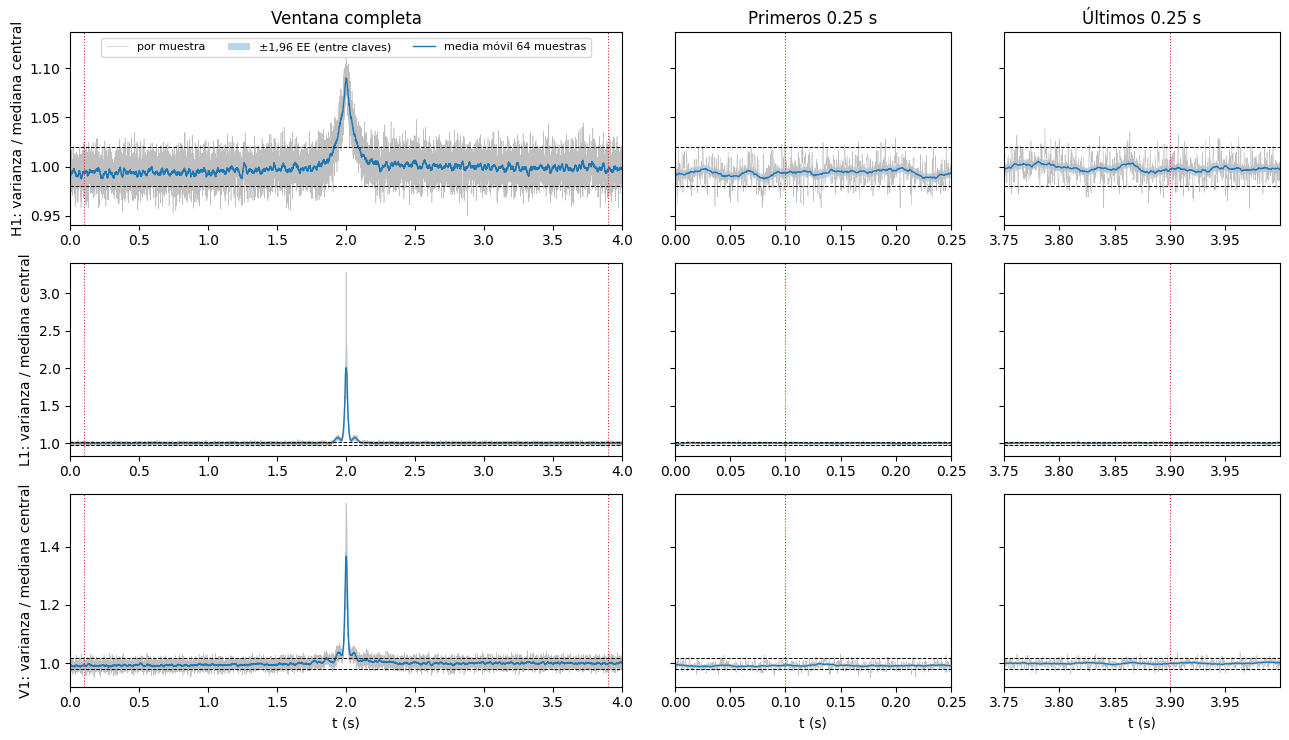

In [4]:
# 4. Stationarity in time (criterion a)
def moving_average(v, w=SMOOTH_SAMPLES):
    # Truncated at the edges, so an edge excursion is not lost and every sample keeps a value.
    n = v.shape[-1]
    c = np.concatenate([np.zeros_like(v[..., :1]), np.cumsum(v, axis=-1)], axis=-1)
    a, b = np.clip(np.arange(n) - w // 2, 0, n), np.clip(np.arange(n) + w // 2, 0, n)
    return (c[..., b] - c[..., a]) / (b - a)


time_s = np.arange(T) / FS
central = slice(T // 4, 3 * T // 4)
var_raw = key_var.mean(axis=0)
stationarity, curves = {}, {}
for d, det in enumerate(DETECTORS):
    smooth_keys = moving_average(key_var[:, d])
    smooth = smooth_keys.mean(axis=0)
    se_smooth = smooth_keys.std(axis=0, ddof=1) / math.sqrt(n_keys)
    se_raw = key_var[:, d].std(axis=0, ddof=1) / math.sqrt(n_keys)
    ref = float(np.median(smooth[central]))
    dev = smooth / ref - 1.0
    dev_raw = var_raw[d] / ref - 1.0
    bad = np.abs(dev) > VAR_LIMIT
    left, right = np.flatnonzero(bad[:T // 2]), np.flatnonzero(bad[T // 2:]) + T // 2
    reach_left = int(left.max()) + 1 if left.size else 0        # samples from the left edge
    reach_right = int(T - right.min()) if right.size else 0     # samples from the right edge
    inner = np.abs(dev[EDGE_LIMIT_SAMPLES:T - EDGE_LIMIT_SAMPLES])
    stationarity[det] = {
        'central_median_var': ref, 'reach_left_samples': reach_left, 'reach_right_samples': reach_right,
        'reach_left_s': reach_left / FS, 'reach_right_s': reach_right / FS, 'n_samples_over_limit': int(bad.sum()),
        'max_abs_dev': float(np.abs(dev).max()), 'max_abs_dev_beyond_edge_limit': float(inner.max()),
        'raw_fraction_over_limit': float((np.abs(dev_raw) > VAR_LIMIT).mean()),
        'pass': bool(max(reach_left, reach_right) <= EDGE_LIMIT_SAMPLES)}
    curves[det] = {'raw': var_raw[d] / ref, 'smooth': smooth / ref, 'se': se_smooth / ref, 'se_raw': se_raw / ref}
    del smooth_keys

raw_expected = math.erfc(VAR_LIMIT / (math.sqrt(2.0 / R) * math.sqrt(2.0)))
print(f'Fraction of raw samples over {VAR_LIMIT:.0%} expected by chance (ideal Gaussian noise): {raw_expected:.3f}')
display(pd.DataFrame(stationarity).T)

fig, axes = plt.subplots(C, 3, figsize=(13, 7.5), sharey='row', gridspec_kw={'width_ratios': [2, 1, 1]})
xlims = [(0, T / FS), (0, ZOOM_S), ((T - 1) / FS - ZOOM_S, (T - 1) / FS)]
titles = ['Ventana completa', f'Primeros {ZOOM_S:g} s', f'Últimos {ZOOM_S:g} s']
for d, det in enumerate(DETECTORS):
    cv = curves[det]
    for j, ax in enumerate(axes[d]):
        ax.plot(time_s, cv['raw'], color='0.75', lw=0.4, rasterized=True, label='por muestra')
        ax.fill_between(time_s, cv['smooth'] - 1.96 * cv['se'], cv['smooth'] + 1.96 * cv['se'],
                        color='C0', alpha=0.3, lw=0, label='±1,96 EE (entre claves)')
        ax.plot(time_s, cv['smooth'], color='C0', lw=1.0, label=f'media móvil {SMOOTH_SAMPLES} muestras')
        for s in (1 - VAR_LIMIT, 1 + VAR_LIMIT):
            ax.axhline(s, color='k', ls='--', lw=0.7)
        for edge in (EDGE_LIMIT_S, (T - 1) / FS - EDGE_LIMIT_S):
            ax.axvline(edge, color='C3', ls=':', lw=0.8)
        ax.set_xlim(xlims[j])
        if d == 0:
            ax.set_title(titles[j])
        if d == C - 1:
            ax.set_xlabel('t (s)')
    axes[d, 0].set_ylabel(f'{det}: varianza / mediana central')
axes[0, 0].legend(loc='upper center', ncol=3, fontsize=8)
fig.tight_layout()
with open(OUT_DIR / FIGS['variance'], 'xb') as f:
    fig.savefig(f, format='png', dpi=150)
plt.show()

,detector,pair,max_abs_dev,signed_dev,f_worst_hz,pass
0,H1,first/central,0.296363,-0.296363,1000.0,False
1,L1,first/central,0.589394,-0.589394,1024.0,False
2,V1,first/central,0.422867,-0.422867,456.0,False
3,H1,last/central,0.237009,-0.237009,1000.0,False
4,L1,last/central,0.577995,-0.577995,1008.0,False
5,V1,last/central,0.398883,-0.398883,456.0,False
6,H1,first/last,0.168209,-0.168209,512.0,False
7,L1,first/last,0.050862,-0.050862,512.0,False
8,V1,first/last,0.165440,-0.165440,900.0,False


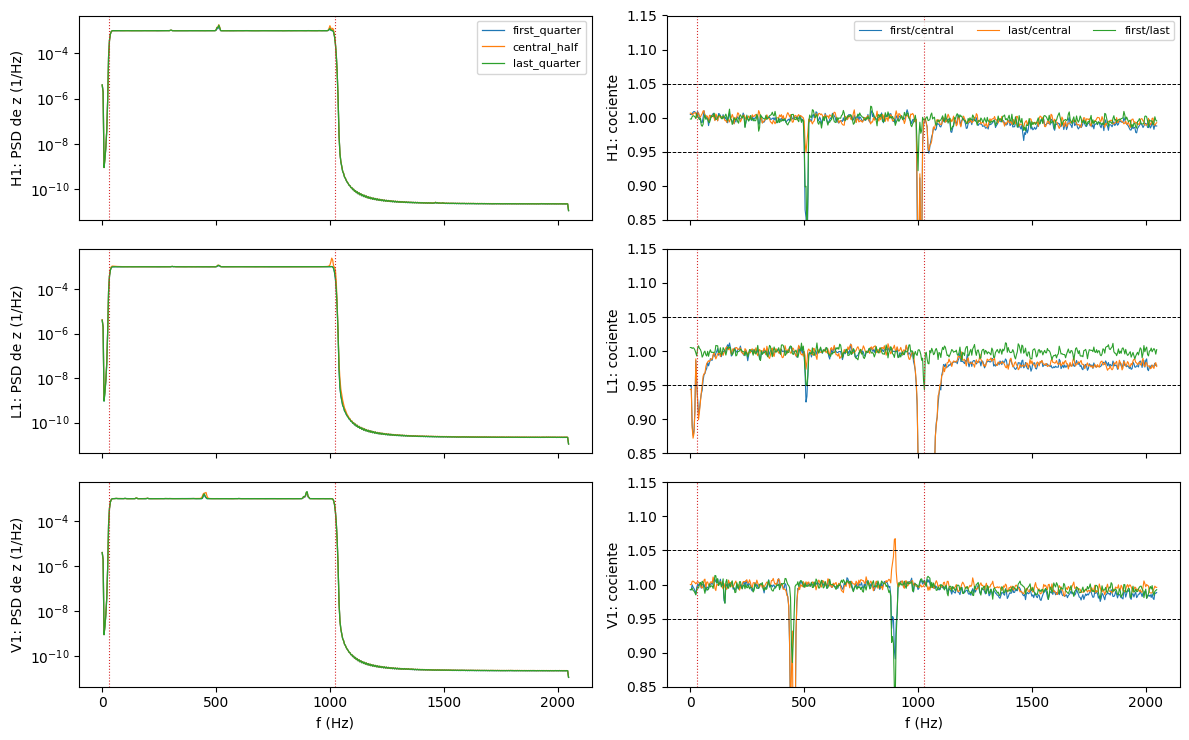

In [5]:
# 5. Spectrum by segment (criterion b)
in_band = (freqs >= BAND_HZ[0]) & (freqs <= BAND_HZ[1])
PAIRS = {'first/central': ('first_quarter', 'central_half'), 'last/central': ('last_quarter', 'central_half'),
         'first/last': ('first_quarter', 'last_quarter')}
ratios, psd_rows = {}, []
for pair, (num, den) in PAIRS.items():
    ratios[pair] = psd[num] / psd[den]
    for d, det in enumerate(DETECTORS):
        dev = ratios[pair][d, in_band] - 1.0
        i = int(np.abs(dev).argmax())
        psd_rows.append({'detector': det, 'pair': pair, 'max_abs_dev': float(np.abs(dev[i])), 'signed_dev': float(dev[i]),
                         'f_worst_hz': float(freqs[in_band][i]), 'pass': bool(np.abs(dev[i]) <= PSD_RATIO_LIMIT)})
display(pd.DataFrame(psd_rows))

fig, axes = plt.subplots(C, 2, figsize=(12, 7.5), sharex=True)
for d, det in enumerate(DETECTORS):
    for name in SEGMENTS:
        axes[d, 0].semilogy(freqs, psd[name][d], lw=0.9, label=name)
    for pair in PAIRS:
        axes[d, 1].plot(freqs, ratios[pair][d], lw=0.8, label=pair)
    for s in (1 - PSD_RATIO_LIMIT, 1 + PSD_RATIO_LIMIT):
        axes[d, 1].axhline(s, color='k', ls='--', lw=0.7)
    for f_edge in BAND_HZ:
        axes[d, 0].axvline(f_edge, color='C3', ls=':', lw=0.8)
        axes[d, 1].axvline(f_edge, color='C3', ls=':', lw=0.8)
    axes[d, 1].set_ylim(0.85, 1.15)
    axes[d, 0].set_ylabel(f'{det}: PSD de z (1/Hz)')
    axes[d, 1].set_ylabel(f'{det}: cociente')
axes[0, 0].legend(fontsize=8)
axes[0, 1].legend(fontsize=8, ncol=3)
axes[-1, 0].set_xlabel('f (Hz)')
axes[-1, 1].set_xlabel('f (Hz)')
fig.tight_layout()
with open(OUT_DIR / FIGS['psd'], 'xb') as f:
    fig.savefig(f, format='png', dpi=150)
plt.show()

In [6]:
# 6. Gaussianity (criterion c)
moment_rows = []
for stat, values in (('skewness', skew), ('excess_kurtosis', kurt)):
    mean = values.mean(axis=0)
    ci_lo, ci_hi = pointwise_ci(boot_means(values))
    for d, det in enumerate(DETECTORS):
        includes_0 = bool(ci_lo[d] <= 0.0 <= ci_hi[d])
        small = bool(abs(mean[d]) < MOMENT_LIMIT)
        moment_rows.append({'detector': det, 'statistic': stat, 'mean': float(mean[d]), 'ci_lo': float(ci_lo[d]),
                            'ci_hi': float(ci_hi[d]), 'ci_includes_0': includes_0, 'abs_lt_limit': small,
                            'pass': includes_0 or small})
display(pd.DataFrame(moment_rows))

,detector,statistic,mean,ci_lo,ci_hi,ci_includes_0,abs_lt_limit,pass
0,H1,skewness,0.000511,0.000125,0.000904,False,True,True
1,L1,skewness,0.000243,-0.000175,0.000669,True,True,True
2,V1,skewness,-0.000220,-0.000604,0.000168,True,True,True
3,H1,excess_kurtosis,-0.000124,-0.000909,0.000607,True,True,True
4,L1,excess_kurtosis,0.131158,0.114146,0.149060,False,False,False
5,V1,excess_kurtosis,0.023267,0.019990,0.026874,False,True,True


,detector,series,max_abs_t,tau_worst,A_at_worst,crit_c,n_point_ci_excl_0,within_band
0,H1,data,3.075006,13,-0.000518,3.603243,5,True
1,H1,reversed,3.075006,13,0.000518,3.603243,5,True
2,H1,white,2.088010,47,0.000274,3.625848,1,True
3,L1,data,3.107910,44,-0.000532,3.603243,7,True
4,L1,reversed,3.107910,44,0.000532,3.603243,7,True
5,L1,white,2.511434,37,0.000362,3.625848,2,True
6,V1,data,1.901538,54,0.000316,3.603243,0,True
7,V1,reversed,1.901538,54,-0.000316,3.603243,0,True
8,V1,white,2.448120,57,0.000330,3.625848,3,True


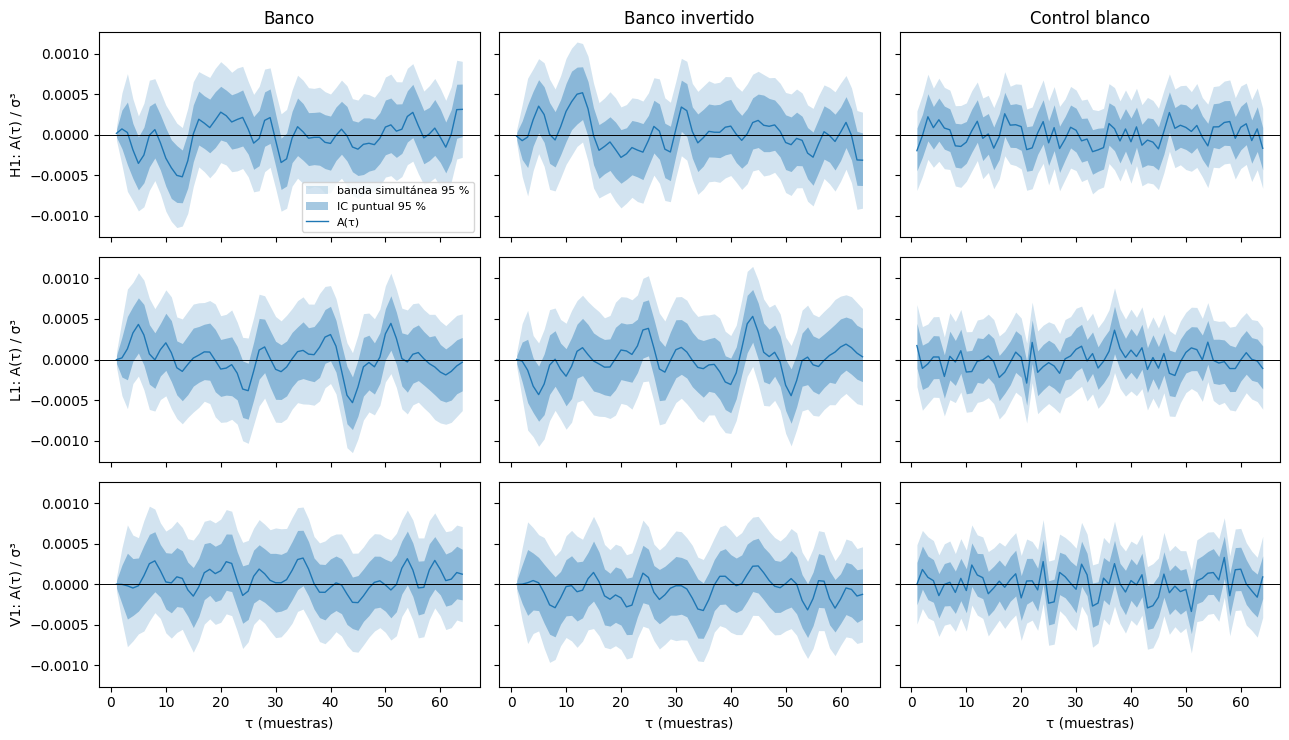

In [7]:
# 7. Irreversibility (criterion d)
irrev_rows = []
for d, det in enumerate(DETECTORS):
    for name, res in irr.items():
        i = int(res['t_obs'][d].argmax())
        irrev_rows.append({'detector': det, 'series': name, 'max_abs_t': float(res['t_obs'][d, i]), 'tau_worst': int(TAUS[i]),
                           'A_at_worst': float(res['mean'][d, i]), 'crit_c': res['crit'],
                           'n_point_ci_excl_0': int(res['n_point_excl_0'][d].sum()),
                           'within_band': bool(res['t_obs'][d].max() <= res['crit'])})
display(pd.DataFrame(irrev_rows))

SERIES_LABEL = {'data': 'Banco', 'reversed': 'Banco invertido', 'white': 'Control blanco'}
fig, axes = plt.subplots(C, 3, figsize=(13, 7.5), sharex=True, sharey=True)
for d, det in enumerate(DETECTORS):
    for j, (name, res) in enumerate(irr.items()):
        ax = axes[d, j]
        ax.fill_between(TAUS, res['mean'][d] - res['band'][d], res['mean'][d] + res['band'][d],
                        color='C0', alpha=0.2, lw=0, label='banda simultánea 95 %')
        ax.fill_between(TAUS, res['ci_lo'][d], res['ci_hi'][d], color='C0', alpha=0.4, lw=0, label='IC puntual 95 %')
        ax.plot(TAUS, res['mean'][d], color='C0', lw=1.0, label='A(τ)')
        ax.axhline(0, color='k', lw=0.7)
        if d == 0:
            ax.set_title(SERIES_LABEL[name])
        if d == C - 1:
            ax.set_xlabel('τ (muestras)')
    axes[d, 0].set_ylabel(f'{det}: A(τ) / σ³')
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
with open(OUT_DIR / FIGS['irrev'], 'xb') as f:
    fig.savefig(f, format='png', dpi=150)
plt.show()

In [8]:
# 8. Pre-fixed reading (with the amendment of 6-11-2026) and summary JSON
fails = []
for det, s in stationarity.items():
    if not s['pass']:
        fails.append(f"(a) {det}: deviations > {VAR_LIMIT:.0%} reach {s['reach_left_s']:.3f} s from the left edge and "
                     f"{s['reach_right_s']:.3f} s from the right edge (limit {EDGE_LIMIT_S} s); "
                     f"max |dev| beyond the limit = {s['max_abs_dev_beyond_edge_limit']:.2%}")
for r in psd_rows:
    if not r['pass']:
        fails.append(f"(b) {r['detector']} {r['pair']}: {r['signed_dev']:+.2%} at {r['f_worst_hz']:g} Hz")
for r in moment_rows:
    if not r['pass']:
        fails.append(f"(c) {r['detector']} {r['statistic']}: {r['mean']:+.4f} [{r['ci_lo']:+.4f}, {r['ci_hi']:+.4f}]")
data_rows = [r for r in irrev_rows if r['series'] == 'data']
for r in data_rows:
    if not r['within_band']:
        fails.append(f"(d) {r['detector']}: tau = {r['tau_worst']}, A = {r['A_at_worst']:+.2e}, "
                     f"|t| = {r['max_abs_t']:.2f} > c = {r['crit_c']:.2f}")

passed = {'a': all(s['pass'] for s in stationarity.values()), 'b': all(r['pass'] for r in psd_rows),
          'c': all(r['pass'] for r in moment_rows), 'd': all(r['within_band'] for r in data_rows)}
verdict = 'simetria compatible' if all(passed.values()) else 'simetria NO compatible'
white_ok = all(r['within_band'] for r in irrev_rows if r['series'] == 'white')

print('\n'.join(f"({k}) {'PASS' if v else 'FAIL'}" for k, v in passed.items()))
print(f'White control within the simultaneous band: {white_ok}')
print(f'\nVEREDICTO: {verdict}')
if fails:
    print('Condiciones que fallan:\n  ' + '\n  '.join(fails))
if not white_ok:
    print('Note: the white control left its band (about 5 % of runs by construction); review before reading (d).')

summary = {
    'run_utc': RUN_UTC,
    'verdict': verdict,
    'criteria_passed': passed,
    'failures': fails,
    'amendment': {'date': '2026-11-06', 'decided_before_data': True,
                  'a': f'moving average of {SMOOTH_SAMPLES} samples sets the verdict; raw curve descriptive',
                  'd': 'simultaneous 95 % max-|t| band over 192 tests sets the verdict; pointwise CIs descriptive'},
    'provenance': {'bank_X': str(MM_DIR / 'bank_X.npy'), 'bank_X_size_bytes': (MM_DIR / 'bank_X.npy').stat().st_size,
                   'bank_X_mtime_ns': (MM_DIR / 'bank_X.npy').stat().st_mtime_ns,
                   'bank_X_sha256_manifest': manifest['outputs_sha256']['bank_X.npy'],
                   'manifest_sha256': hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
                   'shape': [R, C, T], 'n_psd_keys': n_keys, 'k_per_key': K},
    'settings': {'detectors': DETECTORS, 'fs_hz': FS, 'var_limit': VAR_LIMIT, 'smooth_samples': SMOOTH_SAMPLES,
                 'edge_limit_s': EDGE_LIMIT_S, 'psd_ratio_limit': PSD_RATIO_LIMIT, 'band_hz': list(BAND_HZ),
                 'welch_nperseg': NPERSEG, 'moment_limit': MOMENT_LIMIT, 'taus': TAUS.tolist(), 'n_boot': N_BOOT,
                 'seed': SEED, 'white_seed': WHITE_SEED, 'ci_level': CI_LEVEL},
    'stationarity': {'per_detector': stationarity, 'raw_fraction_expected_by_chance': raw_expected},
    'psd_ratios': psd_rows,
    'moments': moment_rows,
    'irreversibility': {'summary': irrev_rows, 'reversal_max_abs_sum': sign_gap, 'white_within_band': white_ok,
                        'curves': {name: {'detectors': DETECTORS, 'crit_c': res['crit'], 'mean': res['mean'].tolist(),
                                          'se': res['se'].tolist(), 'ci_lo': res['ci_lo'].tolist(),
                                          'ci_hi': res['ci_hi'].tolist()} for name, res in irr.items()}},
    'figures': list(FIGS.values()),
}
with open(OUT_DIR / JSON_NAME, 'x') as f:
    json.dump(summary, f, indent=2)
print(f'\nsaved: {OUT_DIR / JSON_NAME}')

(a) FAIL
(b) FAIL
(c) FAIL
(d) PASS
White control within the simultaneous band: True

VEREDICTO: simetria NO compatible
Condiciones que fallan:
  (a) H1: deviations > 2% reach 2.000 s from the left edge and 2.000 s from the right edge (limit 0.1 s); max |dev| beyond the limit = 9.03%
  (a) L1: deviations > 2% reach 2.000 s from the left edge and 2.000 s from the right edge (limit 0.1 s); max |dev| beyond the limit = 100.76%
  (a) V1: deviations > 2% reach 2.000 s from the left edge and 2.000 s from the right edge (limit 0.1 s); max |dev| beyond the limit = 36.71%
  (b) H1 first/central: -29.64% at 1000 Hz
  (b) L1 first/central: -58.94% at 1024 Hz
  (b) V1 first/central: -42.29% at 456 Hz
  (b) H1 last/central: -23.70% at 1000 Hz
  (b) L1 last/central: -57.80% at 1008 Hz
  (b) V1 last/central: -39.89% at 456 Hz
  (b) H1 first/last: -16.82% at 512 Hz
  (b) L1 first/last: -5.09% at 512 Hz
  (b) V1 first/last: -16.54% at 900 Hz
  (c) L1 excess_kurtosis: +0.1312 [+0.1141, +0.1491]

saved: 